Projet = Analyse GRF course via le jeu de données publics de Fukuchi et al. (2017, PeerJ)
1) Chargement des données et filtrage du signal
2) Détecter les contacts au sol aevc un seuil 20/50N
3) Calculer le temps de contact, pic d'impact, loading rate moyen + instantané
4) Normalisation 0-100% appuis

In [65]:
# Import les librairies 
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, filtfilt, find_peaks 

# Paramètre de l'analyse
DOSSIER = Path("data")
SUJET = "RBDS023"
VITESSES = {"T25" : 2.5, # vitese réelle (m/s)
           "T35" : 3.5, 
           "T45" : 4.5}

FS = 300  # Hz : fréquence d'échantillonnage 
FC = 50  # Hz : fréquence de coupure filtre passe-bas
ORDRE = 4   # ordre du filtre Butterworth (standard biomécnaique)
SEUIL = 50. # N : force au-dessus de laquelle => pied est au sol
TC_MIN, TC_MAX = 0.10, 0.50   # s : durée d'appuis en course 
G = 9.81    # m/s² => accélération de la pesanteur

plt.rcParams["figure.figsize"] = (10,4)  # taille par défaut des figures 
plt.rcParams["axes.grid"] = True

for code_v in VITESSES:
    chemin = DOSSIER / f"{SUJET}run{code_v}forces.txt"
    print(("✅" if chemin.exists() else "❌ INTROUVABLE :"), chemin)







✅ data/RBDS023runT25forces.txt
✅ data/RBDS023runT35forces.txt
✅ data/RBDS023runT45forces.txt


1) Chargement des données récupéré via Figshare

In [66]:
NOMS_COLONNES = ["Time", "Fx", "Fy", "Fz", "COPx", "COPy", "COPz", "Ty"]

def charger_forces(chemin):
    ''' on lit le fichier force Fukuchi pour renvoyer un DataFrame propres'''
    # 1) on cherche combien de ligne d'en tête il faut sauter:
    # lit le fichier et on s'arrete à la 1ère ligne où il y a que des nombres 
    with open(chemin) as f:
        for n_entete, ligne in enumerate(f):
            try:
                [float(x) for x in ligne.split()]  # essai convertir chaque morceau en nombre
                break                               # succés = 1ère ligne de donnée
            except ValueError:
                continue 
    
    # 2) on lit les données 
    df = pd.read_csv(chemin, sep=r"\s+", skiprows=n_entete, header=None)

    # 3) on nommes les colonnes mais attention si il manque des colonnes
    if df.shape[1] == len(NOMS_COLONNES):
        df.columns = NOMS_COLONNES
    else:
        print(f" attention {df.shape[1]} colonnes trouvées au lieu de 8 : il faut vérifier")
    return df

# On teste les vitesses intermédaires
df = charger_forces(DOSSIER / f"{SUJET}runT35forces.txt")
print("Dimensions :", df.shape, "→ soit", round(df.shape[0] / FS, 1), "secondes à", FS, "Hz")
df.head() 





Dimensions : (9000, 8) → soit 30.0 secondes à 300 Hz


,Time,Fx,Fy,Fz,COPx,COPy,COPz,Ty
0,1,-55.16,952.61,9.46,2483.31,0,982.17,-13313.60
1,2,-58.82,1098.79,95.44,2482.47,0,986.60,156.92
2,3,-124.66,1076.97,73.70,2496.80,0,982.53,-4092.42
3,4,-139.16,1013.03,46.46,2459.65,0,988.94,47825.10
4,5,-132.60,1083.37,11.29,2492.01,0,981.53,-5226.28


In [67]:
# Vérification de la fréquence d"échantillonnage via les données  pour voir si cela match bien
# 4) colonne Time contient des numéros d'échantillons pas des secondes => temps (s) = (numéro - 1) / fc echanti
if np.median(np.diff(df["Time"])) == 1:
    df["Time"] = (df["Time"] - 1) / FS

dt = np.median(np.diff(df["Time"])) # écart de temps entre deux échantillons
print(f"Pas de temps = {dt:.5f} s => fréquence = {1/dt:.1f} Hz (attendu : {FS} Hz)")

df.describe().round(1)

Pas de temps = 0.00333 s => fréquence = 300.0 Hz (attendu : 300 Hz)


,Time,Fx,Fy,Fz,COPx,COPy,COPz,Ty
count,9000.0,9000.0,9000.0,9000.0,9000.0,9000.0,9000.0,9000.0
mean,15.0,0.8,707.1,2.3,2226.9,0.0,995.3,3235.6
std,8.7,136.4,695.4,28.8,173.6,0.0,35.3,9891.4
min,0.0,-398.6,-0.0,-131.0,1450.1,0.0,855.8,-52481.4
25%,7.5,-42.2,-0.0,-8.0,2149.0,0.0,976.7,-0.0
50%,15.0,-0.0,519.9,-0.0,2149.0,0.0,976.7,-0.0
75%,22.5,57.0,1374.6,13.4,2376.4,0.0,1022.7,7430.2
max,30.0,293.4,1962.3,139.8,2984.4,0.0,1181.6,64013.2


On trouve la colonne force verticale, on sait que force verticale en course peut monte ± 3 x pdc soit 2000 N
On trace les 3 compoantes pour la reconnaitre 

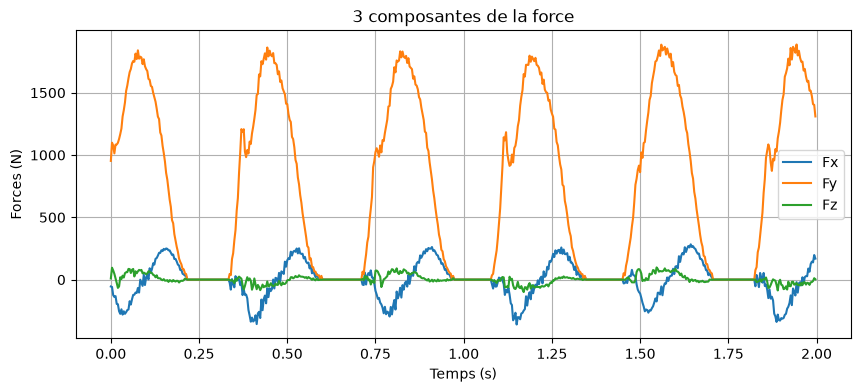

In [68]:
fen = df["Time"] < 2    # masque booléen : True pour les 2 premières secondes
for c in ["Fx", "Fy", "Fz"]:
    plt.plot(df.loc[fen,"Time"], df.loc[fen, c], label=c)
plt.xlabel("Temps (s)")
plt.ylabel("Forces (N)")
plt.title ("3 composantes de la force")
plt.legend()
plt.show()

In [69]:
def force_verticale(df):
    '''Renvoie la force verticale (np.array, en N, positive vers le haut)'''
    forces = df[["Fx", "Fy", "Fz"]]

    # colonne verticale est celle qui a la plus grande amplitude ( abs() = valeur absolue, max() => maximum, idxmax() => nom de la colonne)
    col = forces.abs().max().idxmax()
    fv = df[col].to_numpy()  # tableau Numpy

    # Vérification du signe : on regarde les grandes valeurs d'appuis mais pas tout le signal
    # pendant la phase aérienne, force est ~0 et donc son signe ne veut rien dire 
    grandes = fv[np.abs(fv) > 0.5 * np.abs(fv).max()]
    if np.median(grandes) < 0:
        fv = -fv
        print("Signal Inversé (force verticale était enregistrée négative)")
    
    print(f"Colonne verticale = {col}")
    return fv
fv_brut = force_verticale(df)
print(f"Force verticale max = {fv_brut.max():.0f} N")

Colonne verticale = Fy
Force verticale max = 1962 N


2) Etape 2 : filtrer le signal 
filtre = Butterworth = standard biomécanique
Ordre = 4
Application = filtfilt (aller-retour)
Fréquence coupure = 50hz

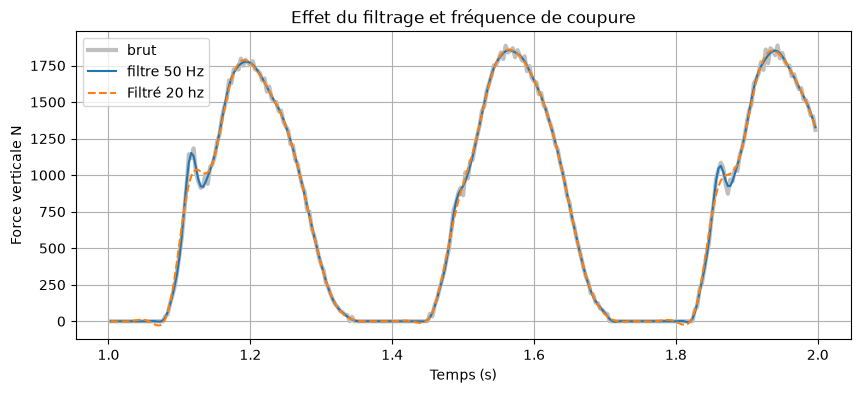

In [70]:
def filtre_passe_bas(signal, fc=FC, fs=FS, ordre=ORDRE):
    '''Filtre passe-bas Butterworth déphasage nul'''
    b, a = butter(ordre, fc, btype="low", fs=fs) # butter() calcule coefficient b,a du filtre
    return filtfilt(b, a, signal) # applciation du filtre aller-retour

fv = filtre_passe_bas(fv_brut)

# comparasion visuelle : brut vs filtré 50 hz vs filtré 20hz sur 1 seconde
t = df["Time"].to_numpy()
fen = (t > 1) & (t < 2)
plt.plot(t[fen], fv_brut[fen], color=".75", lw=3, label="brut")
plt.plot(t[fen], fv[fen], label=f"filtre {FC} Hz")
plt.plot(t[fen], filtre_passe_bas(fv_brut, fc=20)[fen], "--", label="Filtré 20 hz")
plt.xlabel("Temps (s)")
plt.ylabel("Force verticale N")
plt.title("Effet du filtrage et fréquence de coupure")
plt.legend()
plt.show()



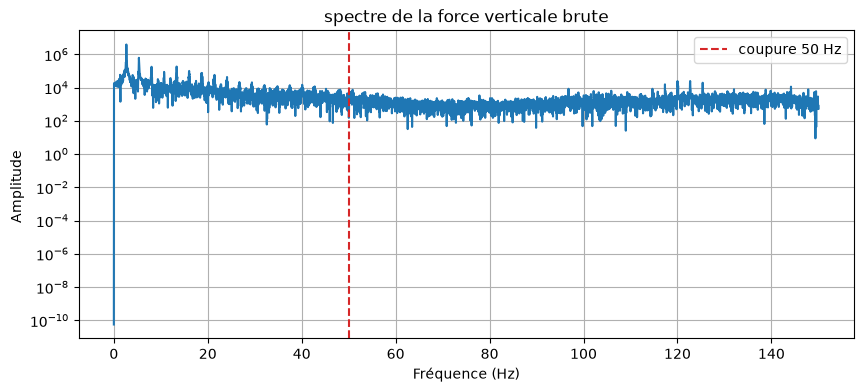

In [71]:
# regarde le contenu fréquentil du signal pour justifier la coupure avec les données , on calcule le spectre d'amplitude avec la FFT
spectre = np.abs(np.fft.rfft(fv_brut - fv_brut.mean()))  # on retire la moyenne pour ne pas écraser le graphe avec composante 0 hz
freqs = np.fft.rfftfreq(len(fv_brut), d=1/FS)   # fréquences correspondantes

plt.semilogy(freqs, spectre)
plt.axvline(FC, color="C3", ls="--", label=f"coupure {FC} Hz")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude ")
plt.title("spectre de la force verticale brute")
plt.legend()
plt.show()



Nous observons que la fréquence de pas se situe à 3 hz soit le coureur pose un pied 3 fois par seconde soit une cadence de 180pas/min.
L'analyse spectrale montre que l'amplitude décroit vers 50hz puis atteint un plateau qui correspond à du bruit de mesure. une fréquence de coupure de 50Hz constitue un compromis entre préservation du signal et réduction du bruit



3) Détection des appuis 

79 appuis gardés, 0 rejetés


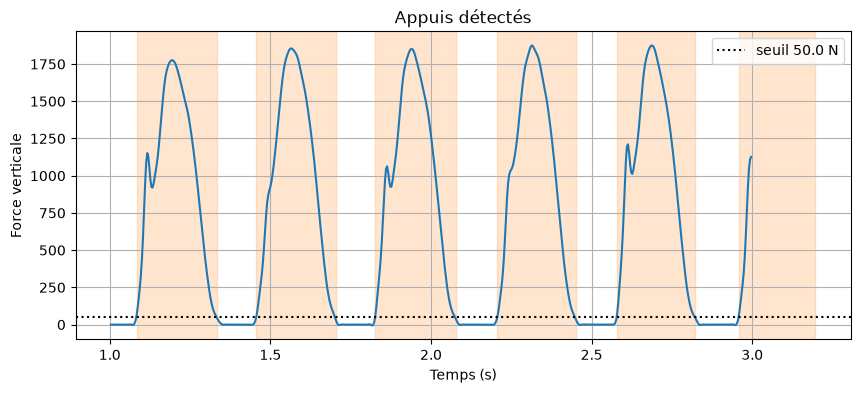

In [72]:
def detecter_appuis(fv, seuil=SEUIL, fs=FS, tc_min=TC_MIN, tc_max=TC_MAX):
    '''renvoie une liste de tuple(indice_debut, indice de fin), un par appui'''
    au_sol = (fv > seuil).astype(int)  # 1 si pied est au sol sinon 0
    d = np.diff(au_sol)    # +1 au contact, -1 au décollage, 0 sinon
    debuts = np.where(d == 1)[0] + 1   # +1 car diff décale d'un indice
    fins = np.where(d == -1)[0] + 1

    # On agrde seulement les fins qui arrivent après le début 
    fins = fins[fins > debuts[0]]

    # uitlisation de zip() pour s'arreter automatiquement à la liste la plus courte => associe chaque début à sa fin
    appuis = []
    for deb, fin in zip(debuts, fins):
        duree = (fin - deb) / fs     # durée en secondes = nombre d'échantillons / fs
        # On rejette les appuis aberrants 
        if tc_min <= duree <= tc_max:
            appuis.append((deb, fin))

    n_rejetes = min(len(debuts), len(fins)) - len(appuis)
    print(f"{len(appuis)} appuis gardés, {n_rejetes} rejetés")
    return appuis

appuis = detecter_appuis(fv)

# Contrôle visuelle : on colorie chaque appuis détecté
fen = (t > 1) & (t < 3)
plt.plot(t[fen], fv[fen])
for deb, fin in appuis:
    if 1 < t[deb] < 3:
        plt.axvspan(t[deb], t[fin], color="C1", alpha=.2)
plt.axhline(SEUIL, color="k", ls=":", label=f"seuil {SEUIL} N")
plt.xlabel("Temps (s)")
plt.ylabel("Force verticale")
plt.title("Appuis détectés")
plt.legend()
plt.show()






In [73]:
# On voudrait que le signal soit idéalement de 0N en phase aérienne 
en_l_air = fv < SEUIL
print(f"Force moyenne en phase aérienne = {fv[en_l_air].mean():.1f} N (idéalement proche de 0)")

# Cadence => super indicateur de course 
duree_totale = (appuis[-1][0] - appuis[0][0]) / FS
cadence = (len(appuis) - 1) / duree_totale * 60
print(f"Cadence = {cadence:.0f} pas/min")

Force moyenne en phase aérienne = 3.2 N (idéalement proche de 0)
Cadence = 160 pas/min


4) Normlaisation au poids du corps 
Important de normaliser car un coureur + lourd produira plus de force 
Probleme => pas de poids dans le fichier
Utilisation théoreme quantité de mouvement 
   E F = m.a => fv - mg = m.av
   soit course stable = pas de variation donc on simplifie
   fv = mg soit BW
   



In [74]:
def estimer_poids(fv, appuis):
    '''Poids du corps (N) = force verticale moyenne sur un nombre entier de pas'''
    i0 = appuis[0][0]  # debut du premier appuis
    i1 = appuis[-1][0]  # debut du dernier appuis => soit entre les deux = nombre entier de pas
    return fv[i0:i1].mean()
BW = estimer_poids(fv, appuis)
print(f"Poids estimé = {BW:.0f} N = masse = {BW / G:.1f} kg")


Poids estimé = 705 N = masse = 71.9 kg


5) Variables de chaque appui
temps de contact (tc) = durée de l'appui (s)
pic d'impact = 1er pic dans les 30 premiers % de l'appuis
pic acitf = max de l'appui soit milieu BW
VALR = pente moyenne de la force entre 20% - 80% du pic d'impact (BW/s)
VILR = pente instantanée maxiamle 

{'tc_s': 0.243, 'pic_impact_BW': 1.671, 'pic_actif_BW': 2.61, 'VALR_BW_s': 67.041, 'VILR_BW_s': 85.637}


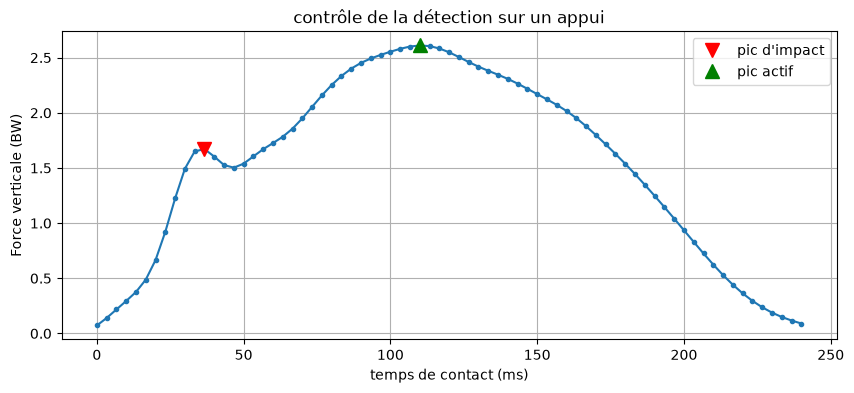

In [75]:
def variables_appui (f, fs=FS):
    '''f = force verticale d'un appuis, déjà en BW, renvoi dinctionnaire de variables'''
    n = len(f)
    tc = n / fs   # temps de contact
    pic_actif = f.max()  # max de l'appui

    # --- Pic d'imapct ---
    # on cherche les pics dans les 30 premiers % de l'appui
    # prominence=0.05 BW : soit un pic doit "depasser" ses voisins d'au moins 0.05 BW pour compter pour ignorer le bruit
    zone = f[: int(0.30 *n)]
    pics, _ = find_peaks(zone, prominence=.05)
    if len(pics) > 0:
        i_imp = pics[0]  # Le premier pic de la zone = pic d'impact
        pic_impact = f[i_imp]
    else:
        i_imp = int(round(0.13 * n))    # convention si pas de pic d'impact
        pic_impact = np.nan  # nan et pas 0 : pic n'existe pas

    # --- Loading rates sur la fenetre 20-80%
    f_ref = f[i_imp]       # force de référence = force au point d'imapact
    montee = f[:i_imp +1]  # portion de l'appui entre le contact et l'impact 

    #np.argmax(tableau_booléen) renvoi l'indice du premier true => premier passage au dessus 20 e dernier 90
    i20 = np.argmax(montee >= 0.2 * f_ref)
    i80 = np.argmax(montee >= 0.8 * f_ref)

    if i80 > i20:
        valr = (f[i80] - f[i20]) / ((i80 - i20) / fs)   # Δ Force / Δ temps (BW/s)
        derivee = np.gradient(f) * fs   # dérivée point par point
        vilr = derivee[i20 : i80 + 1].max()         # pente isntantanée max dans la fenetre 
    else:
        valr = vilr = np.nan

    return {"tc_s" : tc, "pic_impact_BW" : pic_impact, "pic_actif_BW" : pic_actif, "VALR_BW_s" : valr, "VILR_BW_s" : vilr}

# tester sur un appuis, avec un graphique pour contrôler
deb, fin = appuis[50]
f = fv[deb:fin] / BW     # on passe en BW en divisant par le poids
v = variables_appui(f)
print({k: round(float(x), 3) for k, x in v.items()})

temps_ms = np.arange(len(f)) / FS * 1000
plt.plot(temps_ms, f, "o-", ms=3)    # "o-" : affiche les échantillons 
if not np.isnan(v["pic_impact_BW"]):
    i_imp = np.argmin(np.abs(f[: int(0.3 * len(f))] - v["pic_impact_BW"]))
    plt.plot(temps_ms[i_imp], f[i_imp], "rv", ms=10, label="pic d'impact")
plt.plot(temps_ms[np.argmax(f)], f.max(), "g^", ms=10, label="pic actif")
plt.xlabel("temps de contact (ms)")
plt.ylabel("Force verticale (BW)")
plt.title("contrôle de la détection sur un appui")
plt.legend()
plt.show()



6) Normalisation pour chaque appui de 0 à 100%

In [76]:
def normaliser_101(x):
    '''ré-échantillonne un signal sur 101 points'''
    axe_ancien = np.linspace(0, 100, len(x)) # % de l'appuis de chaque échantillon d'origine
    axe_nouveau = np.linspace(0, 100, 101)
    return np.interp(axe_nouveau, axe_ancien, x) # interpolation linéaire entre les points existants 

# on applique à tous les appuis => une matrice 
courbes = np.array([normaliser_101(fv[d:f] / BW) for d, f in appuis])
print("Matrice des courbes :", courbes.shape)



Matrice des courbes : (79, 101)


7) Pipeline complet sur les 3 vitesses avec 3 fichiers 

In [77]:
def analyser_essai(chemin):
    '''Piple complet piour un fichier = renvoie (tableau des variables, matrice des courbes, BW)'''
    df = charger_forces(chemin)
    fv = filtre_passe_bas(force_verticale(df))
    appuis = detecter_appuis(fv)
    BW = estimer_poids(fv, appuis)

    lignes, courbes = [], []
    for d, f in appuis:
        appui = fv[d:f] / BW # un appuis en BW
        lignes.append(variables_appui(appui)) # ses variables
        courbes.append(normaliser_101(appui)) # courbe normaisée
    return pd.DataFrame(lignes), np.array(courbes), BW

# boucles pour les 3 vitesses 
resultats = [] # liste de tabelaux, soit 1 pas vitesse 
toutes_courbes = {} # dictionnaire vitesse => matrice des courbes
for code_v, vitesse in VITESSES.items():
    print(f"\n--- {vitesse} m/s ---")
    tab, crb, bw = analyser_essai(DOSSIER / f"{SUJET}run{code_v}forces.txt")
    tab["vitesse_m_s"] = vitesse      # on ajoute la vitesse comme colonne pour grouper si on veut
    resultats.append(tab)
    toutes_courbes[vitesse] = crb
    print(f"BW estimé = {bw:.0f} N ({bw/G:.1f} kg)")

# empile les 3 tableaux en 1
resultats = pd.concat(resultats, ignore_index=True)
resultats.head()









--- 2.5 m/s ---
Colonne verticale = Fy
77 appuis gardés, 0 rejetés
BW estimé = 705 N (71.9 kg)

--- 3.5 m/s ---
Colonne verticale = Fy
79 appuis gardés, 0 rejetés
BW estimé = 705 N (71.9 kg)

--- 4.5 m/s ---
Colonne verticale = Fy
85 appuis gardés, 0 rejetés
BW estimé = 703 N (71.7 kg)


,tc_s,pic_impact_BW,pic_actif_BW,VALR_BW_s,VILR_BW_s,vitesse_m_s
0,0.276667,1.504795,2.453962,47.410293,59.960497,2.5
1,0.276667,NaN,2.439119,42.302227,53.972132,2.5
2,0.276667,1.509904,2.411853,48.992342,61.111104,2.5
3,0.273333,NaN,2.450145,44.607753,54.145904,2.5
4,0.270000,1.471614,2.425695,46.313680,63.526605,2.5


In [78]:
# Tableau récapitulatif de tous les données
recap = resultats.groupby("vitesse_m_s").agg(["mean", "std"]).round(3)
recap

tc_s        pic_impact_BW        pic_actif_BW        VALR_BW_s  \
              mean    std          mean    std         mean    std      mean   
vitesse_m_s                                                                    
2.5          0.276  0.004         1.459  0.074        2.430  0.036    43.124   
3.5          0.244  0.003         1.651  0.083        2.606  0.042    52.972   
4.5          0.213  0.004         1.908  0.114        2.747  0.056    87.506   

                    VILR_BW_s          
                std      mean     std  
vitesse_m_s                            
2.5           5.902    55.075   8.136  
3.5           9.890    66.224  12.164  
4.5          12.932   101.124  12.109

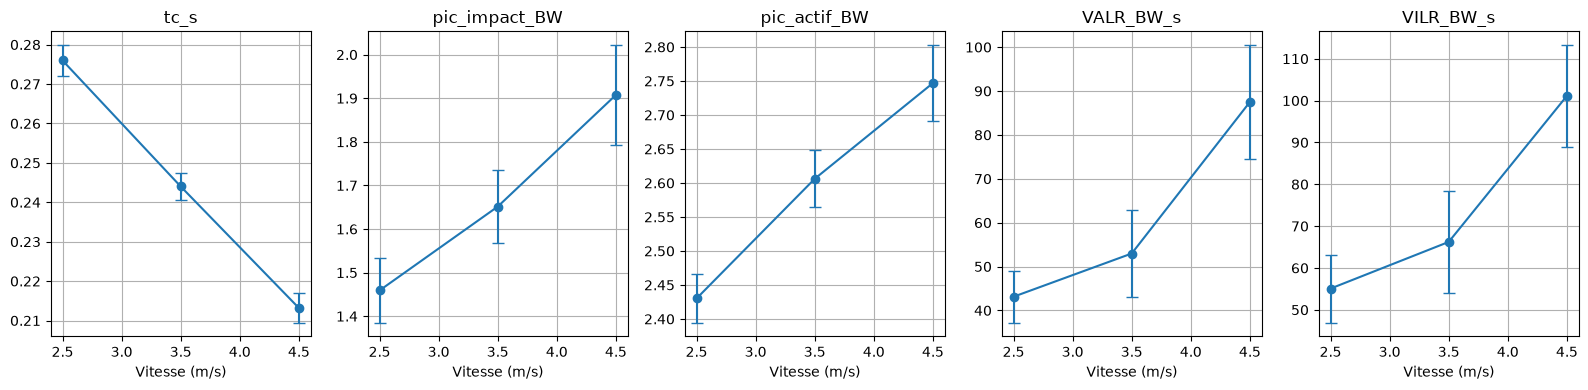

% d'appuis sans pic d'impact : {2.5: 62.3, 3.5: 49.4, 4.5: 9.4}


In [79]:
# une figure par variable 
variables = ["tc_s", "pic_impact_BW", "pic_actif_BW", "VALR_BW_s", "VILR_BW_s"]
fig, axes = plt.subplots(1, len(variables), figsize=(16,4))
for ax, var in zip(axes, variables):
    g = resultats.groupby("vitesse_m_s")[var]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values, marker="o", capsize=4)
    ax.set_title(var)
    ax.set_xlabel("Vitesse (m/s)")
plt.tight_layout()
plt.show()

# Proportion d'appui sans pic d'impact à chaque vitesse
sans_pic = resultats.groupby("vitesse_m_s")["pic_impact_BW"].apply(lambda s:100 * s.isna().mean())
print("% d'appuis sans pic d'impact :", sans_pic.round(1).to_dict())





In [80]:
# Variation relative entre 2.5 et 4.5 m/s : quelle est la varibale la plus sensible à la vitesse
moy = resultats.groupby("vitesse_m_s").mean()
variation = 100 * (moy.loc[4.5] - moy.loc[2.5]) / moy.loc[2.5]
print("Variation entre 2.5 et 4.5 m/s (%):")
print(variation.round(1))

# Sauvegarde des résultats : on garde une trace des chiffres pour que cela sout réutilisable
resultats.to_csv(f"resultats_{SUJET}.csv", index=False)
recap.to_csv(f"recap_{SUJET}.csv")
print("Resultats sauvegardés")






Variation entre 2.5 et 4.5 m/s (%):
tc_s             -22.8
pic_impact_BW     30.7
pic_actif_BW      13.0
VALR_BW_s        102.9
VILR_BW_s         83.6
dtype: float64
Resultats sauvegardés


In [82]:
# 1) pour chaque appui 
a_un_pic = resultats["pic_impact_BW"].notna()
resultats["a_pic_impact"] = a_un_pic
pourcentage = 100 * resultats.groupby("vitesse_m_s")["a_pic_impact"].mean()

print("% d'appuis avec pic d'imapact:")
print(pourcentage.round(1))

% d'appuis avec pic d'imapact:
vitesse_m_s
2.5    100.0
3.5    100.0
4.5    100.0
Name: a_pic_impact, dtype: float64


Interprétation des résultats 
1 - Temps de contact diminue avec une augmentation de la vitesse de course
Sur un cycle de course, le sol va fournir une impulsion verticale qui doit compenser le poids. Plus on va vite, plus le pied va passer vite sous le corps et donc le temps d'appuis de celui ci diminue.

2 - Augmentation de 30%  du pict d'impact, VALRD de 102% et VILR de 83%
Soit un VALRD de + 102% veut dire que le loading rate moyen double entre les deux vitese => soit la force verticale monte deux fois plus vite au debut de l'appuis qu'a 2.5 m/s
VILRD + 83% => pente instantanée maximale est multiplié par 1.83

3 - Pic d'actif augmentent moins que le VARLD car VARLD = force divisée par un temps soit la vitesse qui augmente = augmentation pic d'impact divisé par diminution temps

4 - Limites de l'étude 
- uniquement analyse d'un sujet 